# Student Performance & Study Group Analyzer

**Name:** G Anirudh
**Register No.:** RA2411003012249

This notebook reads a CSV of student grades and attendance, cleans it, summarises the class with
statistics, estimates pass and 'A' grade probabilities from the data, and pairs students into
study buddies using cosine similarity between their grade vectors.

| Phase | Subject | What happens here |
|---|---|---|
| 1. Data Setup | Python & Analytics | Generate and load the CSV, fill missing marks, bar chart of class averages |
| 2. Stat Analysis | Statistics | Mean, median, standard deviation; attendance vs performance correlation |
| 3. Pass/Fail Odds | Probability | Empirical probability of passing, scoring an A, scoring above 80% |
| 4. Study Buddy Match | Linear Algebra | Dot product / cosine similarity between grade vectors, pairing |

In [1]:
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.precision", 2)
plt.rcParams["figure.dpi"] = 110
SUBJECTS = ["Math_Score", "Science_Score", "English_Score"]

## Phase 1: Data Setup

### 1.1 Generate the dataset
This is the script from the project statement. One change: the original seeds NumPy but not
Python's `random` module, so the rows that lose a Math mark change on every run. Adding
`random.seed(42)` keeps the results in this notebook reproducible.

In [2]:
np.random.seed(42)
random.seed(42)   # added so the missing-value rows are the same every run

first_names = ["Aarav", "Vivaan", "Aditya", "Vihaan", "Arjun", "Sai", "Ayaan", "Krishna",
               "Ishaan", "Shaurya", "Ananya", "Aadhya", "Diya", "Saanvi", "Priya", "Neha",
               "Riya", "Kriti", "Pooja", "Kavya", "Rahul", "Rohan", "Amit", "Karan",
               "Vikram", "Sneha", "Nidhi", "Tanvi", "Rashi", "Meera"]

data = []
for name in first_names:
    attendance = np.random.randint(60, 101)
    base_score = attendance * 0.8   # ties grades to attendance
    math_grade = min(100, max(0, int(np.random.normal(base_score, 10))))
    science_grade = min(100, max(0, int(np.random.normal(base_score, 8))))
    english_grade = min(100, max(0, int(np.random.normal(base_score + 5, 7))))
    if random.random() < 0.05:      # simulate a missing Math mark
        math_grade = np.nan
    data.append([name, math_grade, science_grade, english_grade, attendance])

df_gen = pd.DataFrame(data, columns=["Student_Name", "Math_Score", "Science_Score",
                                     "English_Score", "Attendance_Pct"])
df_gen.to_csv("student_data.csv", index=False)
print("Saved student_data.csv with", len(df_gen), "rows")

Saved student_data.csv with 30 rows


### 1.2 Load and inspect the CSV

In [3]:
df = pd.read_csv("student_data.csv")
print(df.shape)
df.head(10)

(30, 5)


,Student_Name,Math_Score,Science_Score,English_Score,Attendance_Pct
0,Aarav,72.0,82,86,98
1,Vivaan,NaN,61,60,78
2,Aditya,79.0,68,81,95
3,Vihaan,69.0,66,72,89
4,Arjun,78.0,76,51,80
5,Sai,75.0,71,69,87
6,Ayaan,53.0,56,52,62
7,Krishna,66.0,62,70,84
8,Ishaan,70.0,54,76,79
9,Shaurya,NaN,73,82,94


In [4]:
df.info()
print("\nMissing values per column:")
print(df.isnull().sum())

<class 'pandas.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Student_Name    30 non-null     str    
 1   Math_Score      26 non-null     float64
 2   Science_Score   30 non-null     int64  
 3   English_Score   30 non-null     int64  
 4   Attendance_Pct  30 non-null     int64  
dtypes: float64(1), int64(3), str(1)
memory usage: 1.3 KB

Missing values per column:
Student_Name      0
Math_Score        4
Science_Score     0
English_Score     0
Attendance_Pct    0
dtype: int64


### 1.3 Handle missing values
A missing mark is filled with that subject's class mean. With 30 students, dropping a row would
throw away the student's other two subjects and their attendance, which we still need for the
correlation and the buddy matching.

In [5]:
missing_rows = df[df[SUBJECTS].isnull().any(axis=1)]
print("Rows with a missing mark:")
display(missing_rows)

for col in SUBJECTS:
    df[col] = df[col].fillna(round(df[col].mean(), 1))

print("Missing values after cleaning:", int(df.isnull().sum().sum()))
df["Overall_Avg"] = df[SUBJECTS].mean(axis=1).round(2)
df.loc[missing_rows.index]

Rows with a missing mark:


,Student_Name,Math_Score,Science_Score,English_Score,Attendance_Pct
1,Vivaan,NaN,61,60,78
9,Shaurya,NaN,73,82,94
12,Diya,NaN,74,60,67
19,Kavya,NaN,82,72,99


Missing values after cleaning: 0


,Student_Name,Math_Score,Science_Score,English_Score,Attendance_Pct,Overall_Avg
1,Vivaan,67.7,61,60,78,62.90
9,Shaurya,67.7,73,82,94,74.23
12,Diya,67.7,74,60,67,67.23
19,Kavya,67.7,82,72,99,73.90


### 1.4 Bar chart: class average per subject

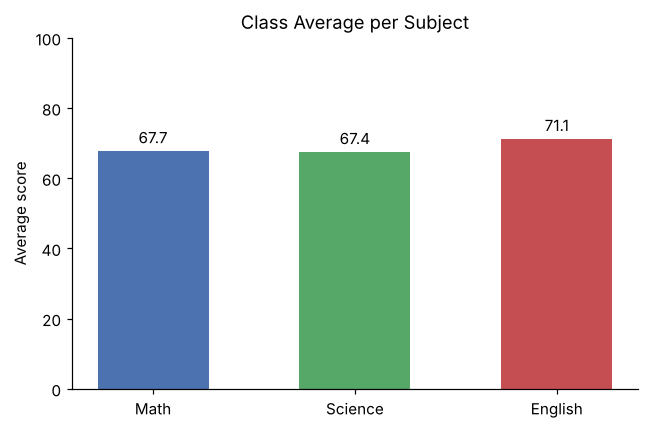

In [6]:
averages = df[SUBJECTS].mean()
labels = [s.replace("_Score", "") for s in SUBJECTS]

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(labels, averages.values, color=["#4C72B0", "#55A868", "#C44E52"], width=0.55)
ax.bar_label(bars, fmt="%.1f", padding=3)
ax.set_ylim(0, 100)
ax.set_ylabel("Average score")
ax.set_title("Class Average per Subject")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("class_averages.png")
plt.show()

## Phase 2: Statistical Analysis

### 2.1 Mean, median and standard deviation
The mean is the class average, the median is the middle score once marks are sorted (it is not
pulled around by a single very low or very high mark), and the standard deviation measures how
far scores typically sit from the mean.

In [7]:
summary = pd.DataFrame({
    "Mean": df[SUBJECTS + ["Overall_Avg"]].mean(),
    "Median": df[SUBJECTS + ["Overall_Avg"]].median(),
    "Std Dev": df[SUBJECTS + ["Overall_Avg"]].std(),     # sample std (n-1)
    "Min": df[SUBJECTS + ["Overall_Avg"]].min(),
    "Max": df[SUBJECTS + ["Overall_Avg"]].max(),
})
summary.index = ["Math", "Science", "English", "Overall"]
summary.round(2)

,Mean,Median,Std Dev,Min,Max
Math,67.66,70.50,12.89,37.0,93.00
Science,67.40,70.50,13.67,36.0,91.00
English,71.13,72.00,10.96,51.0,87.00
Overall,68.73,71.33,10.52,45.0,83.67


To show the formula behind the library call, here is the standard deviation for Math worked out
by hand: $s = \sqrt{\frac{\sum (x_i - \bar{x})^2}{n-1}}$

In [8]:
x = df["Math_Score"].values
mean_x = x.sum() / len(x)
s_manual = np.sqrt(((x - mean_x) ** 2).sum() / (len(x) - 1))
print(f"Math mean (manual)    = {mean_x:.2f}")
print(f"Math std dev (manual) = {s_manual:.2f}")
print(f"Math std dev (pandas) = {df['Math_Score'].std():.2f}")

Math mean (manual)    = 67.66
Math std dev (manual) = 12.89
Math std dev (pandas) = 12.89


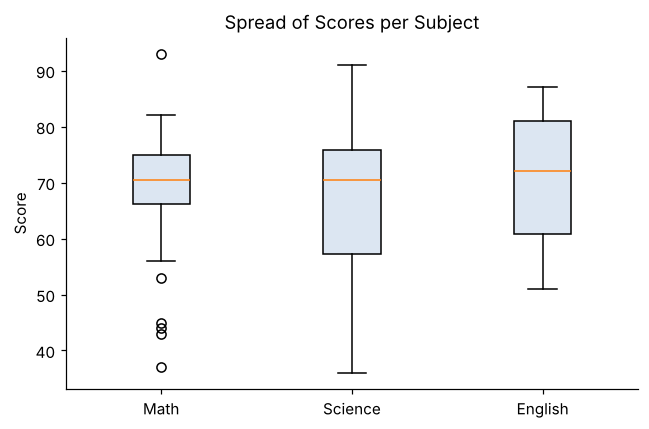

In [9]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.boxplot([df[c] for c in SUBJECTS], tick_labels=labels, patch_artist=True,
           boxprops=dict(facecolor="#DCE6F2"))
ax.set_ylabel("Score")
ax.set_title("Spread of Scores per Subject")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("score_spread.png")
plt.show()

### 2.2 Correlation between attendance and performance
Pearson's r runs from -1 to +1. Values near +1 mean that students who attend more also score
more.

In [10]:
corr = df[["Attendance_Pct"] + SUBJECTS + ["Overall_Avg"]].corr()
print("Correlation of each column with attendance:")
print(corr["Attendance_Pct"].drop("Attendance_Pct").round(3))

r = corr.loc["Attendance_Pct", "Overall_Avg"]
strength = "strong" if abs(r) >= 0.7 else "moderate" if abs(r) >= 0.4 else "weak"
print(f"\nAttendance vs overall average: r = {r:.3f} ({strength} positive relationship)")

Correlation of each column with attendance:
Math_Score       0.75
Science_Score    0.73
English_Score    0.84
Overall_Avg      0.92
Name: Attendance_Pct, dtype: float64

Attendance vs overall average: r = 0.917 (strong positive relationship)


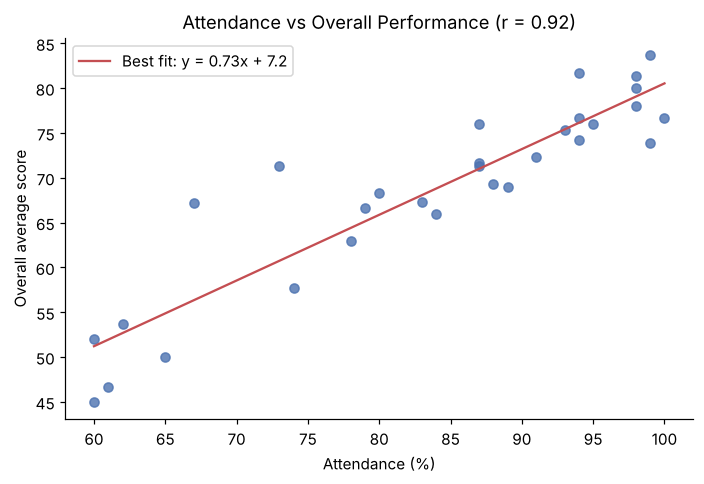

In [11]:
m, c = np.polyfit(df["Attendance_Pct"], df["Overall_Avg"], 1)
xs = np.linspace(df["Attendance_Pct"].min(), df["Attendance_Pct"].max(), 50)

fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.scatter(df["Attendance_Pct"], df["Overall_Avg"], color="#4C72B0", alpha=0.8)
ax.plot(xs, m * xs + c, color="#C44E52", label=f"Best fit: y = {m:.2f}x + {c:.1f}")
ax.set_xlabel("Attendance (%)")
ax.set_ylabel("Overall average score")
ax.set_title(f"Attendance vs Overall Performance (r = {r:.2f})")
ax.legend()
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("attendance_vs_performance.png")
plt.show()

## Phase 3: Pass/Fail Odds (Probability)

Empirical probability is the share of students in the data who meet a condition:

$$P(\text{event}) = \frac{\text{number of students who meet the condition}}{\text{total students}}$$

Thresholds used: **pass = 40 or above**, **A grade = 80 or above**, and the project's
**above 80%** question is checked on each subject and on the overall average.

In [12]:
PASS_MARK, A_MARK = 40, 80
n = len(df)

rows = []
for col, lab in zip(SUBJECTS, labels):
    rows.append({
        "Subject": lab,
        "P(Pass, >=40)": (df[col] >= PASS_MARK).sum() / n,
        "P(A grade, >=80)": (df[col] >= A_MARK).sum() / n,
        "P(Above 80, >80)": (df[col] > A_MARK).sum() / n,
    })
prob = pd.DataFrame(rows).set_index("Subject")
prob.round(3)

,"P(Pass, >=40)","P(A grade, >=80)","P(Above 80, >80)"
Subject,,,
Math,0.97,0.10,0.10
Science,0.93,0.17,0.17
English,1.00,0.33,0.30


In [13]:
p_all_pass = (df[SUBJECTS] >= PASS_MARK).all(axis=1).mean()
p_overall_80 = (df["Overall_Avg"] > 80).mean()
p_any_A = (df[SUBJECTS] >= A_MARK).any(axis=1).mean()

print(f"P(student passes all three subjects)      = {p_all_pass:.3f}")
print(f"P(student scores an A in at least one)    = {p_any_A:.3f}")
print(f"P(random student's overall average > 80%) = {p_overall_80:.3f}")

P(student passes all three subjects)      = 0.900
P(student scores an A in at least one)    = 0.500
P(random student's overall average > 80%) = 0.100


**Conditional probability.** Does attendance change the odds? Splitting the class at 80%
attendance:

In [14]:
high = df[df["Attendance_Pct"] >= 80]
low = df[df["Attendance_Pct"] < 80]
for label, grp in [("Attendance >= 80%", high), ("Attendance <  80%", low)]:
    p = (grp[SUBJECTS] >= A_MARK).any(axis=1).mean()
    print(f"{label}: {len(grp):2d} students, P(at least one A) = {p:.3f}")

Attendance >= 80%: 20 students, P(at least one A) = 0.700
Attendance <  80%: 10 students, P(at least one A) = 0.100


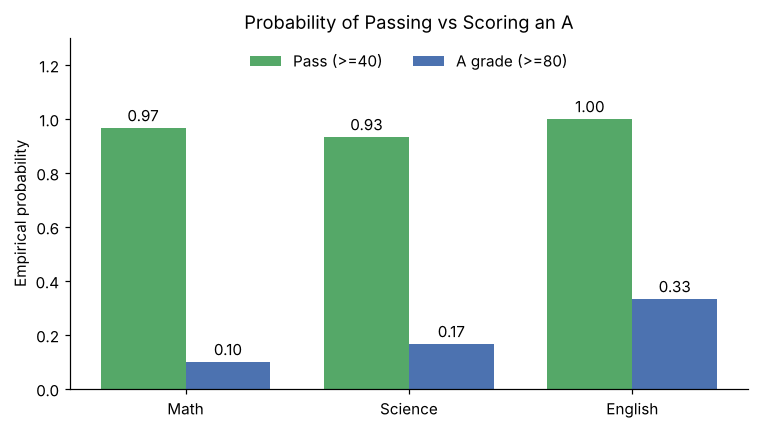

In [15]:
fig, ax = plt.subplots(figsize=(7, 4))
xpos = np.arange(len(labels))
w = 0.38
b1 = ax.bar(xpos - w/2, prob["P(Pass, >=40)"], w, label="Pass (>=40)", color="#55A868")
b2 = ax.bar(xpos + w/2, prob["P(A grade, >=80)"], w, label="A grade (>=80)", color="#4C72B0")
ax.bar_label(b1, fmt="%.2f", padding=2)
ax.bar_label(b2, fmt="%.2f", padding=2)
ax.set_xticks(xpos, labels)
ax.set_ylim(0, 1.3)
ax.set_ylabel("Empirical probability")
ax.set_title("Probability of Passing vs Scoring an A")
ax.legend(loc="upper center", ncol=2, frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("probabilities.png")
plt.show()

## Phase 4: Study Buddy Match (Linear Algebra)

Each student becomes a vector of three marks, e.g. $\vec{a} = [\text{Math}, \text{Science}, \text{English}]$.
Cosine similarity measures the angle between two vectors:

$$\cos\theta = \frac{\vec{a} \cdot \vec{b}}{\lVert\vec{a}\rVert \, \lVert\vec{b}\rVert}$$

A value of 1 means the two profiles point the same way.

### 4.1 A worked example with two students

In [16]:
X_raw = df[SUBJECTS].values.astype(float)
names = df["Student_Name"].values

a, b = X_raw[0], X_raw[1]
dot = np.dot(a, b)
na, nb = np.linalg.norm(a), np.linalg.norm(b)
print(f"{names[0]}: {a}")
print(f"{names[1]}: {b}")
print(f"Dot product      = {dot:.1f}")
print(f"|a| = {na:.2f}, |b| = {nb:.2f}")
print(f"Cosine similarity = {dot / (na * nb):.4f}")

Aarav: [72. 82. 86.]
Vivaan: [67.7 61.  60. ]
Dot product      = 15036.4
|a| = 138.94, |b| = 109.11
Cosine similarity = 0.9919


### 4.2 Why the raw marks need centering first
All marks are positive and sit in a narrow band, so every raw vector points in nearly the same
direction and almost every pair scores close to 1. That makes the ranking useless for matching.

In [17]:
def cosine_matrix(X):
    norms = np.linalg.norm(X, axis=1, keepdims=True)
    norms[norms == 0] = 1
    U = X / norms
    return U @ U.T          # all pairwise dot products of unit vectors

S_raw = cosine_matrix(X_raw)
off = S_raw[~np.eye(len(S_raw), dtype=bool)]
print(f"Raw vectors: similarity ranges from {off.min():.3f} to {off.max():.3f}")

Raw vectors: similarity ranges from 0.929 to 1.000


The fix is to standardise each subject (z-score: subtract the subject mean, divide by its
standard deviation). Now a positive entry means "above the class in this subject" and a negative
entry means "below". Cosine similarity on these vectors compares strength profiles, so it
separates a student who is strong in Math but weak in English from one with the opposite
pattern.

In [18]:
Z = (X_raw - X_raw.mean(axis=0)) / X_raw.std(axis=0)
S = cosine_matrix(Z)
off = S[~np.eye(len(S), dtype=bool)]
print(f"Standardised vectors: similarity ranges from {off.min():.3f} to {off.max():.3f}")

sim_df = pd.DataFrame(S, index=names, columns=names)
sim_df.iloc[:6, :6].round(3)

Standardised vectors: similarity ranges from -0.999 to 0.994


,Aarav,Vivaan,Aditya,Vihaan,Arjun,Sai
Aarav,1.00,-0.95,0.71,0.11,-0.42,0.18
Vivaan,-0.95,1.00,-0.66,-0.17,0.67,0.10
Aditya,0.71,-0.66,1.00,0.76,-0.35,0.41
Vihaan,0.11,-0.17,0.76,1.00,-0.36,0.15
Arjun,-0.42,0.67,-0.35,-0.36,1.00,0.71
Sai,0.18,0.10,0.41,0.15,0.71,1.00


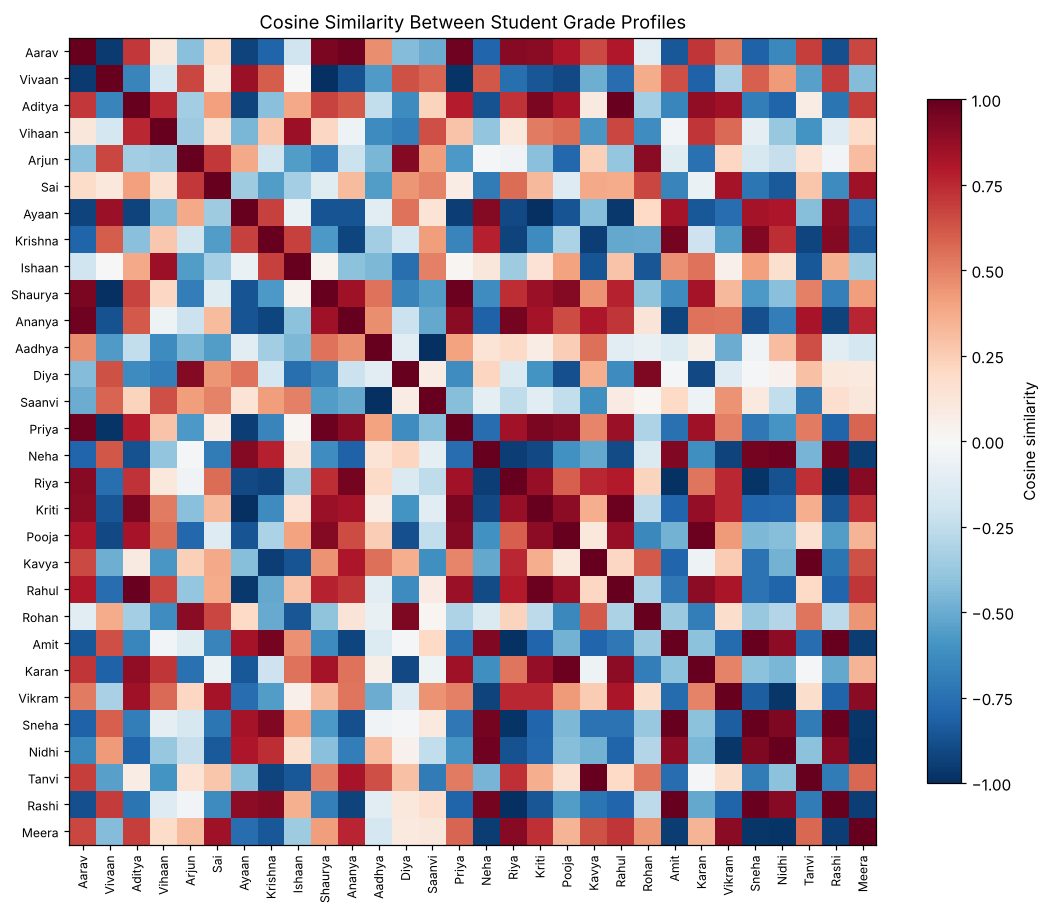

In [19]:
fig, ax = plt.subplots(figsize=(10, 8.5))
im = ax.imshow(S, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(names)), names, rotation=90, fontsize=8)
ax.set_yticks(range(len(names)), names, fontsize=8)
ax.set_title("Cosine Similarity Between Student Grade Profiles")
fig.colorbar(im, ax=ax, shrink=0.8, label="Cosine similarity")
plt.tight_layout()
plt.savefig("similarity_heatmap.png")
plt.show()

### 4.3 Pair students into study buddies
Greedy matching: take the most similar unpaired pair, lock it in, repeat until everyone has a
partner. With 30 students this gives 15 pairs. If the class size were odd, the last student
joins the pair they are most similar to.

In [20]:
def make_pairs(S, names):
    n = len(names)
    candidates = sorted(((S[i, j], i, j) for i in range(n) for j in range(i + 1, n)),
                        reverse=True)
    used, pairs = set(), []
    for sim, i, j in candidates:
        if i not in used and j not in used:
            pairs.append([i, j, sim])
            used.update((i, j))
    leftover = [k for k in range(n) if k not in used]
    groups = [[p[0], p[1]] for p in pairs]
    for k in leftover:   # odd class size: join the closest pair
        best = max(range(len(groups)), key=lambda g: np.mean([S[k, m] for m in groups[g]]))
        groups[best].append(k)
    return pairs, groups

pairs, groups = make_pairs(S, names)

def profile(i):
    return " / ".join(f"{int(v)}" for v in X_raw[i])

buddy_df = pd.DataFrame([{
    "Pair": k + 1,
    "Student A": names[i], "A (M/S/E)": profile(i),
    "Student B": names[j], "B (M/S/E)": profile(j),
    "Cosine Similarity": round(sim, 3),
} for k, (i, j, sim) in enumerate(pairs)])
buddy_df.to_csv("study_buddies.csv", index=False)
buddy_df

,Pair,Student A,A (M/S/E),Student B,B (M/S/E),Cosine Similarity
0,1,Amit,57 / 51 / 65,Sneha,43 / 37 / 60,0.99
1,2,Kavya,67 / 82 / 72,Tanvi,67 / 75 / 72,0.99
2,3,Aditya,79 / 68 / 81,Rahul,78 / 70 / 82,0.99
3,4,Pooja,71 / 68 / 87,Karan,71 / 66 / 80,0.98
4,5,Shaurya,67 / 73 / 82,Priya,71 / 75 / 84,0.98
5,6,Neha,45 / 52 / 59,Nidhi,37 / 50 / 63,0.97
6,7,Aarav,72 / 82 / 86,Ananya,74 / 91 / 86,0.97
7,8,Diya,67 / 74 / 60,Rohan,73 / 85 / 56,0.93
8,9,Krishna,66 / 62 / 70,Rashi,44 / 36 / 55,0.92
9,10,Riya,79 / 85 / 81,Meera,81 / 79 / 74,0.91


Greedy matching pairs the best matches first, so the last few pairs are whoever is left. The
average similarity below shows how good the pairing is overall.

In [21]:
print(f"Average similarity across all pairs: {buddy_df['Cosine Similarity'].mean():.3f}")
print(f"Strongest pair: {buddy_df.iloc[0]['Student A']} & {buddy_df.iloc[0]['Student B']} "
      f"({buddy_df.iloc[0]['Cosine Similarity']:.3f})")
last = buddy_df.iloc[-1]
print(f"Weakest pair:   {last['Student A']} & {last['Student B']} ({last['Cosine Similarity']:.3f})")

Average similarity across all pairs: 0.845
Strongest pair: Amit & Sneha (0.994)
Weakest pair:   Aadhya & Kriti (0.073)


## Final Summary
Everything above, collected into one printed report.

In [22]:
print("=" * 60)
print("        STUDENT PERFORMANCE & STUDY GROUP REPORT")
print("=" * 60)
print(f"Students analysed : {len(df)}")
print(f"Missing marks filled with subject mean: {len(missing_rows)}")
print("\n--- Subject statistics ---")
print(summary.loc[["Math", "Science", "English"], ["Mean", "Median", "Std Dev"]].round(2).to_string())
print(f"\nAttendance vs overall score correlation: r = {r:.3f}")
print("\n--- Probabilities ---")
print(prob.round(3).to_string())
print(f"\nP(pass all subjects)       = {p_all_pass:.3f}")
print(f"P(overall average > 80%)   = {p_overall_80:.3f}")
print("\n--- Study buddy pairs ---")
for _, row in buddy_df.iterrows():
    print(f"  {row['Pair']:2d}. {row['Student A']:<8} + {row['Student B']:<8} "
          f"(similarity {row['Cosine Similarity']:.3f})")
print("=" * 60)

        STUDENT PERFORMANCE & STUDY GROUP REPORT
Students analysed : 30
Missing marks filled with subject mean: 4

--- Subject statistics ---
          Mean  Median  Std Dev
Math     67.66    70.5    12.89
Science  67.40    70.5    13.67
English  71.13    72.0    10.96

Attendance vs overall score correlation: r = 0.917

--- Probabilities ---
         P(Pass, >=40)  P(A grade, >=80)  P(Above 80, >80)
Subject                                                   
Math              0.97              0.10              0.10
Science           0.93              0.17              0.17
English           1.00              0.33              0.30

P(pass all subjects)       = 0.900
P(overall average > 80%)   = 0.100

--- Study buddy pairs ---
   1. Amit     + Sneha    (similarity 0.994)
   2. Kavya    + Tanvi    (similarity 0.993)
   3. Aditya   + Rahul    (similarity 0.989)
   4. Pooja    + Karan    (similarity 0.980)
   5. Shaurya  + Priya    (similarity 0.980)
   6. Neha     + Nidhi    (similarity